--ИМПОРТ БИБЛИОТЕК--

In [16]:
import numpy as np
import matplotlib.pyplot as plt

--РЕАЛИЗАЦИЯ КЛАССА--

In [20]:
class LogisticRegression:
    def __init__(self, lr=0.1, n_iters=1000, reg=0.0, fit_intercept=True):
        self.lr = lr
        self.n_iters = n_iters
        self.reg = reg #l2
        self.fit_intercept = fit_intercept
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1.0 / (1.0 + np.exp(-z))

    def _add_bias(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim == 1:
            X = X.reshape(-1, 1)
        if self.fit_intercept:
            return np.hstack([np.ones((X.shape[0], 1)), X])
        return X

    def _log_loss(self, y, p):
        eps = 1e-12
        p = np.clip(p, eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def fit(self, X, y):
        Xb = self._add_bias(X)
        y = np.asarray(y, dtype=float).ravel()
        n, m = Xb.shape
        w = np.zeros(m)

        self.loss_history = []
        for _ in range(self.n_iters):
            p = self._sigmoid(Xb @ w)
            grad = Xb.T @ (p - y) / n
            if self.fit_intercept:
                grad[1:] += self.reg * w[1:]
            else:
                grad += self.reg * w
            w -= self.lr * grad
            self.loss_history.append(self._log_loss(y, p))

        if self.fit_intercept:
            self.bias = w[0]
            self.weights = w[1:]
        else:
            self.bias = 0.0
            self.weights = w
        return self

    def predict_proba(self, X):
        Xb = self._add_bias(X)
        w = np.concatenate([[self.bias], self.weights]) if self.fit_intercept else self.weights
        return self._sigmoid(Xb @ w)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    @staticmethod
    def _metrics(y_true, y_pred):
        y_true = np.asarray(y_true).ravel()
        y_pred = np.asarray(y_pred).ravel()

        tp = int(np.sum((y_true == 1) & (y_pred == 1)))
        tn = int(np.sum((y_true == 0) & (y_pred == 0)))
        fp = int(np.sum((y_true == 0) & (y_pred == 1)))
        fn = int(np.sum((y_true == 1) & (y_pred == 0)))

        acc = (tp + tn) / len(y_true) if len(y_true) else 0.0
        precision = tp / (tp + fp) if (tp + fp) else 0.0
        recall = tp / (tp + fn) if (tp + fn) else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0

        return {
            "accuracy": acc,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        }

    def score(self, X, y, threshold=0.5):
        return self._metrics(y, self.predict(X, threshold))

    @staticmethod
    def roc_auc(y_true, y_score):
        y_true = np.asarray(y_true).ravel()
        y_score = np.asarray(y_score).ravel()
        pos = y_score[y_true == 1]
        neg = y_score[y_true == 0]
        if len(pos) == 0 or len(neg) == 0:
            return float("nan")
        order = np.argsort(y_score)
        ranks = np.empty_like(order, dtype=float)
        ranks[order] = np.arange(1, len(y_score) + 1)
        n_pos, n_neg = len(pos), len(neg)
        return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

--ВИЗУАЛИЗАЦИЯ--

bias: 0.14
weights: [1.959 1.239]
  accuracy: 0.9625
 precision: 0.9601990049751243
    recall: 0.965
        f1: 0.9625935162094762
        TP: 193
        TN: 192
        FP: 8
        FN: 7
ROC AUC: 0.994


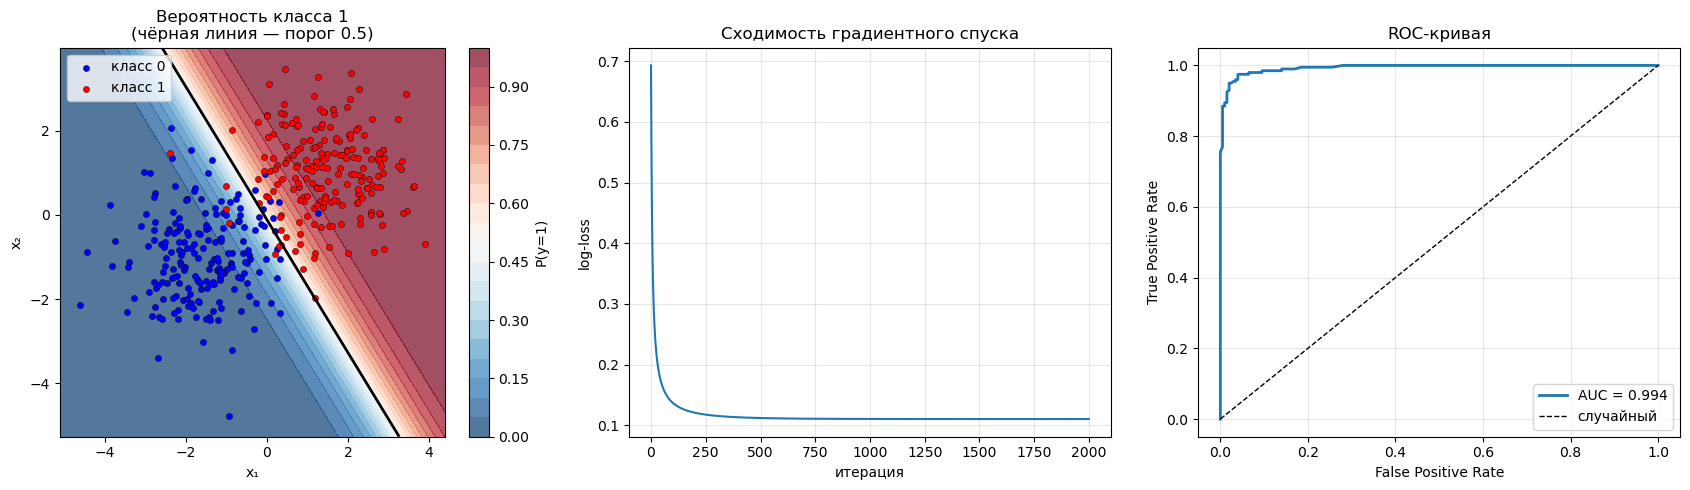

In [23]:
rng = np.random.default_rng(0)

n = 400
X0 = rng.normal([-1.5, -1.0], 1.0, size=(n // 2, 2))   #0
X1 = rng.normal([ 1.5,  1.0], 1.0, size=(n // 2, 2))   #1
X = np.vstack([X0, X1])
y = np.r_[np.zeros(n // 2), np.ones(n // 2)]

model = LogisticRegression(lr=0.1, n_iters=2000, reg=0.01).fit(X, y)

print("bias:", round(model.bias, 3))
print("weights:", np.round(model.weights, 3))
for k, v in model.score(X, y).items():
    print(f"{k:>10}: {v}")
print("ROC AUC:", round(LogisticRegression.roc_auc(y, model.predict_proba(X)), 3))


x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
grid = np.c_[xx.ravel(), yy.ravel()]
proba_grid = model.predict_proba(grid).reshape(xx.shape)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
contour = ax.contourf(xx, yy, proba_grid, levels=20,
                      cmap="RdBu_r", alpha=0.7)
ax.scatter(X[y == 0, 0], X[y == 0, 1], s=20, c="blue",
           edgecolor="k", linewidth=0.3, label="класс 0")
ax.scatter(X[y == 1, 0], X[y == 1, 1], s=20, c="red",
           edgecolor="k", linewidth=0.3, label="класс 1")
ax.contour(xx, yy, proba_grid, levels=[0.5], colors="black", linewidths=2)
ax.set_xlabel("x₁"); ax.set_ylabel("x₂")
ax.set_title("Вероятность класса 1\n(чёрная линия — порог 0.5)")
ax.legend(loc="upper left")
plt.colorbar(contour, ax=ax, label="P(y=1)")

ax = axes[1]
ax.plot(model.loss_history, lw=1.5)
ax.set_xlabel("итерация")
ax.set_ylabel("log-loss")
ax.set_title("Сходимость градиентного спуска")
ax.grid(alpha=0.3)

ax = axes[2]
p = model.predict_proba(X)
thresholds = np.linspace(0, 1, 200)
tprs, fprs = [], []
for t in thresholds:
    pred = (p >= t).astype(int)
    tp = np.sum((y == 1) & (pred == 1))
    fn = np.sum((y == 1) & (pred == 0))
    fp = np.sum((y == 0) & (pred == 1))
    tn = np.sum((y == 0) & (pred == 0))
    tprs.append(tp / (tp + fn) if (tp + fn) else 0)
    fprs.append(fp / (fp + tn) if (fp + tn) else 0)
auc = LogisticRegression.roc_auc(y, p)
ax.plot(fprs, tprs, lw=2, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="случайный")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC-кривая")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()